# Task 1 — Anti-Cheat Detection

โน้ตบุ๊กนี้ทำ Task 1 ทำนาย `is_cheater` แล้วส่งออก `submissions/task1.csv` (คอลัมน์ `id,task1`) เพื่อรวมกับ Task อื่น
ย้ายมาจากโน้ตบุ๊กและสคริปต์ Task 1 ใน repo [i3artuf/CPE342-kaggle-competition](https://github.com/i3artuf/CPE342-kaggle-competition)
ซึ่งเป็นสูตรที่อยู่ใน submission ที่ได้คะแนน Kaggle จริงของกลุ่ม (public 0.74155 และทุกไฟล์หลังจากนั้นจนถึง 0.82618 ใช้คอลัมน์ Task 1 ชุดเดียวกัน)

**Metric: binary F₂ ของคลาส 1 (คนโกง)**

หน้า Overview ของ Kaggle เขียนว่า "F2 Score (Macro)" แต่ผลส่งจริงชี้ว่า Kaggle คิด F₂ ของคลาส 1 อย่างเดียว:
กลุ่มเปลี่ยนเฉพาะ threshold ของ Task 1 จาก 0.38 (จุดที่ Macro F₂ สูงสุด) เป็น 0.20 (จุดที่ binary F₂ สูงสุด) โดยไม่แตะ Task อื่น
คะแนน public รวมขึ้นจาก **0.72752 เป็น 0.74155 (+0.01403)** ถ้า Kaggle ใช้ Macro F₂ คะแนนควรลดลงราว 0.011 แทน

**สูตรที่ส่งจริง (ล็อกไว้ในส่วนที่ 6)**

| ส่วน | ค่า |
|---|---|
| ข้อมูลฝึก | เฉพาะ 90,816 แถวที่มี label (ตัด 13,184 แถวที่ไม่มี label ออก) |
| Features | feature ดิบ 31 ตัว + สร้างเพิ่ม 21 ตัว = 52 ตัว |
| Missingness augmentation | สำเนา train อีกชุด สุ่มปิดค่า 10% ของทุก feature เป็น NaN (seed 42) แล้วต่อท้าย train |
| โมเดล | LightGBM 285 ต้น, learning rate 0.045, num_leaves 31, seed 42 |
| Threshold | 0.20 |

**ลำดับการทำงาน:** โหลดและตรวจข้อมูล **→** ดูค่าว่าง **→** features และ metric **→** เปรียบเทียบ candidates ด้วย 5-fold OOF บน development 80%
**→** ล็อกสูตร **→** ประเมิน audit 20% ครั้งเดียว **→** ฝึกสุดท้ายด้วย label ทั้งหมด **→** ส่งออก

คะแนน OOF และ audit ในโน้ตบุ๊กเป็นคะแนนประเมินภายใน ไม่ใช่คะแนน Kaggle
ไม่ใช้ test เพื่อฝึก เติมค่า หรือเลือก threshold และไม่ใช้ pseudo-label

## 1. ตั้งค่าและ dependencies

ติดตั้งแพ็กเกจด้วย `pip install -r Task1/requirements.txt` จาก root ของ repo แล้วเลือก kernel ของ environment นั้น
รันได้ทั้งจาก root หรือจาก `Task1/notebooks/` เพราะโค้ดหา root ของโปรเจกต์ (โฟลเดอร์ที่มี `data/`) เอง

`FAST_MODE=True` ใช้ตรวจ flow อย่างรวดเร็ว (ลดจำนวน folds และต้นไม้) ผลที่ใช้จริงต้องรัน `FAST_MODE=False` แบบ **Run All**

ผลลัพธ์ที่เขียน:
- `submissions/task1.csv` ผลทำนายสำหรับรวม (ไม่ขึ้น Git)
- `models/Task1/` โมเดล LightGBM, OOF, probabilities และตารางตรวจสอบ (ไม่ขึ้น Git)
- `reports/experiments/task1_run_metadata.json` สรุปพารามิเตอร์ คะแนน และเวอร์ชันแพ็กเกจ

In [1]:
import io, os, sys, json, random, hashlib, zipfile, platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (fbeta_score, roc_auc_score, log_loss,
                             classification_report, confusion_matrix)
from lightgbm import LGBMClassifier, early_stopping

SEED = 42
FAST_MODE = False
N_SPLITS = 3 if FAST_MODE else 5
MAX_ROUNDS = 250 if FAST_MODE else 1000
EARLY_STOPPING = 35 if FAST_MODE else 80
N_JOBS = min(4, os.cpu_count() or 1)
AUDIT_FRACTION = 0.20
MIN_GAIN = 0.002   # do not select a more complex pipeline for a negligible gain
# No source classifier is fitted on competition test features.
RUN_ADVERSARIAL = False
RUN_MISSINGNESS_STRESS = True
# หา root ของโปรเจกต์ (โฟลเดอร์ที่มี data/) จะได้รันจากโฟลเดอร์ไหนก็ได้
ROOT = Path.cwd()
while not (ROOT / 'data').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'data' / 'raw' / 'Task1'
OUTPUT_DIR = ROOT / 'models' / 'Task1'                  # โมเดลและไฟล์ตรวจสอบ (ไม่ขึ้น Git)
SUBMISSION_PATH = ROOT / 'submissions' / 'task1.csv'    # ผลทำนายสำหรับรวม (ไม่ขึ้น Git)
REPORT_PATH = ROOT / 'reports' / 'experiments' / 'task1_run_metadata.json'
for folder in (OUTPUT_DIR, SUBMISSION_PATH.parent, REPORT_PATH.parent):
    folder.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
PACKAGE_VERSIONS = {p: version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'lightgbm']}
print('Python:', platform.python_version(), '| packages:', PACKAGE_VERSIONS)
print('FAST_MODE:', FAST_MODE, '| CV folds:', N_SPLITS, '| project root:', ROOT.resolve())


Python: 3.13.3 | packages: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0'}
FAST_MODE: False | CV folds: 5 | project root: C:\Users\copte\Player-Intelligence-System-CPE342-ML


## 2. อ่านข้อมูลและตรวจรุ่นข้อมูล

อ่าน `train.csv`, `test.csv`, `datacard.txt` จาก `data/raw/Task1/` และ `sample_submission.csv` จาก `data/raw/`
ตรวจ SHA256 ของ `train.csv` ให้ตรงกับรุ่นที่ใช้ตอนได้คะแนน (ชุดข้อมูลที่ TA refresh เมื่อ 12 พ.ย. 2026)
ไม่นำตัวเลขใน sample submission มาใช้เป็น label ใช้เพียงลำดับ `id` เท่านั้น

In [2]:
EXPECTED_TRAIN_SHA256 = 'd8dbdcaf8f9d042d2490a0dfd01b730cea3112717131f7f04d573f52958941d4'
for name in ['train.csv', 'test.csv', 'datacard.txt']:
    if not (DATA_DIR / name).is_file():
        raise FileNotFoundError(f'วาง {name} ของ Task 1 (01_binary_classification) ไว้ที่ {DATA_DIR}')
TRAIN_SHA256 = hashlib.sha256((DATA_DIR / 'train.csv').read_bytes()).hexdigest()
TEST_SHA256 = hashlib.sha256((DATA_DIR / 'test.csv').read_bytes()).hexdigest()
assert TRAIN_SHA256 == EXPECTED_TRAIN_SHA256, 'train.csv ไม่ใช่รุ่นเดียวกับที่ใช้ตอนได้คะแนน'
source = DATA_DIR
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
datacard = (DATA_DIR / 'datacard.txt').read_text(encoding='utf-8-sig')
sample_path = ROOT / 'data' / 'raw' / 'sample_submission.csv'
sample_submission = pd.read_csv(sample_path, sep=None, engine='python') if sample_path.is_file() else None
print('Source:', source.relative_to(ROOT))
print('Train:', train.shape, '| test:', test.shape)
print('train.csv SHA256:', TRAIN_SHA256)
print('test.csv  SHA256:', TEST_SHA256)
print(datacard)
if sample_submission is not None:
    print('Sample submission columns:', sample_submission.columns.tolist(), '| rows:', len(sample_submission))

Source: data\raw\Task1
Train: (104000, 33) | test: (25889, 32)
train.csv SHA256: d8dbdcaf8f9d042d2490a0dfd01b730cea3112717131f7f04d573f52958941d4
test.csv  SHA256: ebbd887109474a8bc060734f21211ca316d4dcf85ef577c0aca26d91644090b1
TASK 1: ANTI-CHEAT DETECTION

TARGET VARIABLE: is_cheater (Binary)
Binary classification: 0=Legitimate Player, 1=Cheater

FEATURES (31 features):

1. kill_death_ratio (float)
   Ratio of kills to deaths

2. headshot_percentage (float)
   Percentage of kills that are headshots[1]

3. win_rate (float)
   Percentage of matches won

4. accuracy_score (float)
   Overall shooting accuracy score

5. kill_consistency (float)
   Variance in kill performance (higher = more consistent)

6. reaction_time_ms (float)
   Average reaction time in milliseconds

7. account_age_days (float)
   Days since account creation

8. level (float)
   Current player level

9. level_progression_speed (float)
   Rate of level advancement

10. friend_network_size (float)
    Number of in-game

In [3]:
TARGET, ID = 'is_cheater', 'player_id'
assert TARGET in train.columns and TARGET not in test.columns
assert ID in train.columns and ID in test.columns
features = [c for c in test.columns if c != ID]
assert set(train.columns) == set(test.columns) | {TARGET}
assert len(features) == 31 and len(test) == 25889, 'Check competition dataset version'
assert train[ID].notna().all() and test[ID].notna().all()
assert train[ID].is_unique and test[ID].is_unique
assert not set(train[ID]).intersection(test[ID])
assert set(train[TARGET].dropna().unique()) == {0, 1}
assert all(pd.api.types.is_numeric_dtype(train[c]) and pd.api.types.is_numeric_dtype(test[c]) for c in features)
labeled = train.loc[train[TARGET].notna()].reset_index(drop=True).copy()
unlabeled = train.loc[train[TARGET].isna()].reset_index(drop=True).copy()
y_all = labeled[TARGET].astype('int8')
# Fail rather than allowing identical feature vectors to leak across train/validation.
assert not labeled.duplicated(subset=features).any(), 'Duplicate vectors: use grouped CV before training'
train_hashes = pd.util.hash_pandas_object(labeled[features], index=False)
test_hashes = pd.util.hash_pandas_object(test[features], index=False)
assert not train_hashes.isin(test_hashes).any(), 'Exact train/test feature overlap requires investigation'
dev_idx, audit_idx = train_test_split(np.arange(len(labeled)), test_size=AUDIT_FRACTION,
                                    stratify=y_all, random_state=2026)
dev = labeled.iloc[dev_idx].reset_index(drop=True)
audit = labeled.iloc[audit_idx].reset_index(drop=True)
y = dev[TARGET].astype('int8')
folds = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(dev, y))
assert not set(dev[ID]).intersection(audit[ID])
print('Labeled:', len(labeled), '| unlabeled (excluded from supervision):', len(unlabeled))
print('Development:', len(dev), '| audit:', len(audit), '| test:', len(test))
display(y.value_counts().rename_axis('development_label').to_frame('n'))
TEST_ID_HASH = hashlib.sha256('\n'.join(test[ID].astype(str)).encode()).hexdigest()
print('Test ID/order SHA256:', TEST_ID_HASH)


Labeled: 90816 | unlabeled (excluded from supervision): 13184
Development: 72652 | audit: 18164 | test: 25889


,n
development_label,
0,47272
1,25380


Test ID/order SHA256: 757cc75b90d1fe9e3e41674df7bf2dbb5db97fbf25430593424d79cd4a4ec99b


## 3. ดูค่าว่างและการกระจายของข้อมูล

ตาราง missing rate ของ train และ test ใช้ดูเชิงพรรณนาเท่านั้น
ไม่ใช้ test หรือสถิติของ test ในการฝึก สร้าง augmentation เลือก threshold หรือกำหนดสัดส่วน masking 10%

,development,unlabeled_train,test,test_minus_development
avg_session_length_min,0.2293,0.2326,0.0158,-0.2136
aiming_smoothness,0.2075,0.2130,0.0206,-0.1869
friend_network_size,0.2233,0.2294,0.0474,-0.1759
account_age_days,0.1437,0.1423,0.0056,-0.1382
movement_pattern_score,0.2238,0.2214,0.0872,-0.1365
team_play_score,0.1957,0.1934,0.0813,-0.1145
headshot_percentage,0.0276,0.0244,0.1411,0.1135
survival_time_avg,0.2428,0.2481,0.1306,-0.1123
clutch_success_rate,0.0249,0.0225,0.1353,0.1104
spray_control_score,0.1657,0.1687,0.0557,-0.1100


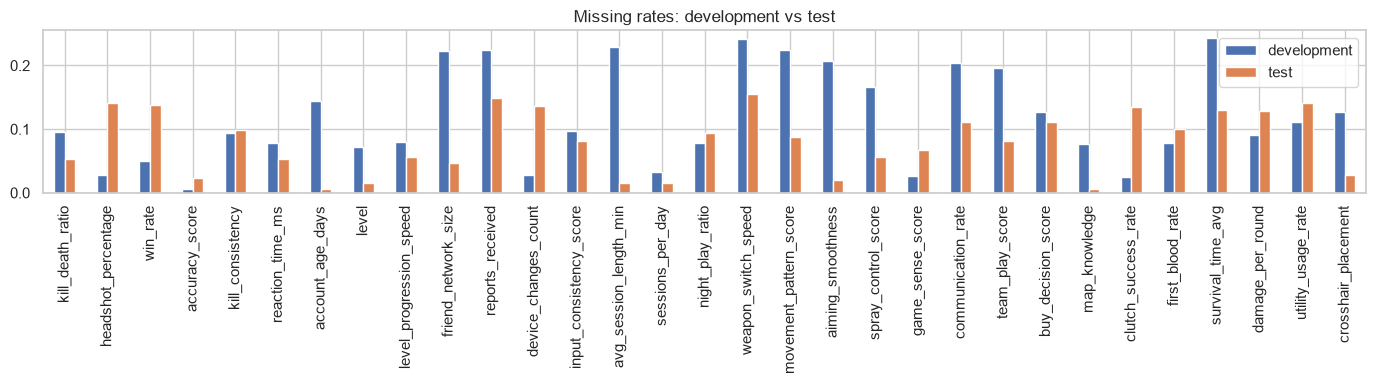

,feature,ks_stat
30,crosshair_placement,0.011057
12,input_consistency_score,0.010833
21,communication_rate,0.010770
28,damage_per_round,0.010632
2,win_rate,0.009790
23,buy_decision_score,0.009774
1,headshot_percentage,0.008777
17,movement_pattern_score,0.008637
29,utility_usage_rate,0.008496
0,kill_death_ratio,0.008000


,development_target_correlation
reports_received,-0.336634
crosshair_placement,-0.227612
kill_death_ratio,-0.136015
headshot_percentage,-0.133923
game_sense_score,-0.126685
account_age_days,-0.096020
accuracy_score,-0.088524
level,-0.082207
spray_control_score,-0.076812
aiming_smoothness,-0.067948


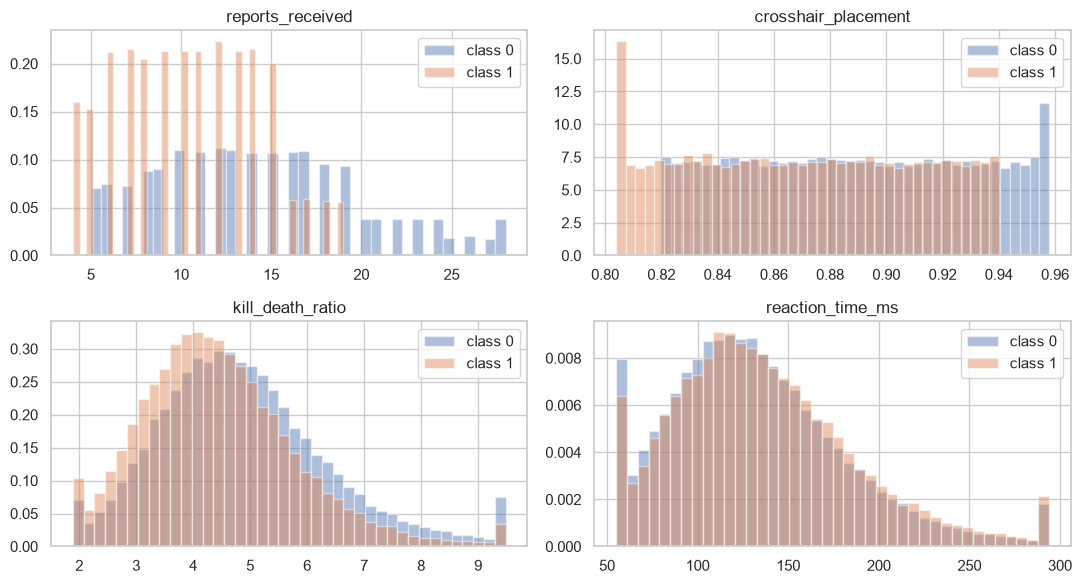

In [4]:
missing = pd.DataFrame({'development': dev[features].isna().mean(),
                        'unlabeled_train': unlabeled[features].isna().mean(),
                        'test': test[features].isna().mean()})
missing['test_minus_development'] = missing['test'] - missing['development']
display(missing.sort_values('test_minus_development', key=abs, ascending=False).round(4))
missing[['development', 'test']].plot.bar(figsize=(14, 4), title='Missing rates: development vs test')
plt.tight_layout(); plt.show()
ks_table = pd.DataFrame([{'feature': c, 'ks_stat': ks_2samp(dev[c].dropna(), test[c].dropna(), method='asymp').statistic}
                         for c in features]).sort_values('ks_stat', ascending=False)
display(ks_table.head(12))
corr = dev[features + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET)
display(corr.sort_values(key=abs, ascending=False).to_frame('development_target_correlation'))
columns = ['reports_received', 'crosshair_placement', 'kill_death_ratio', 'reaction_time_ms']
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for col, ax in zip(columns, axes.flat):
    lo, hi = dev[col].quantile([.01, .99])
    for cls in (0, 1):
        ax.hist(dev.loc[y == cls, col].dropna().clip(lo, hi), bins=40, density=True, alpha=.45, label=f'class {cls}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()


## 4. Features และ metric

Feature engineering คำนวณทีละแถว ไม่ใช้ target หรือสถิติของชุดอื่น
`signal_only` กำหนดล่วงหน้าจากสัญญาณที่พบในผลรันเดิม เป็น candidate เพื่อทดสอบเท่านั้น

Metric คือ **binary F₂ ของคลาส 1** = 5·TP / (5·TP + 4·FN + FP) ตามที่ Kaggle ใช้จริง (ดูหัวโน้ตบุ๊ก)
F₂ ให้น้ำหนัก recall มากกว่า precision จึงคุ้มที่จะทายว่าโกงมากขึ้น threshold ที่ดีที่สุดจึงต่ำกว่า 0.5 มาก
Threshold search คำนวณ confusion counts ด้วย cumulative sums และตรวจกับ `sklearn.metrics.fbeta_score`
มี `macro_f2` ไว้แสดงเปรียบเทียบเท่านั้น ไม่ใช้เลือกโมเดลหรือ threshold

อ้างอิง: [scikit-learn F-beta](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.fbeta_score.html)
และ [LightGBM early stopping](https://lightgbm.readthedocs.io/en/stable/Python-Intro.html#early-stopping)

In [5]:
# 8. Leakage-safe feature builder (row-wise, deterministic; no target, no global statistics)
def build_features(df, engineered=False):
    x=df[features].copy()
    x=x.replace([np.inf,-np.inf],np.nan).astype('float32')
    if not engineered:return x
    eps=np.float32(1e-3)
    def ratio(a,b): return x[a]/(x[b].abs()+eps)
    x['n_missing']=x.isna().sum(axis=1).astype('float32')
    x['headshot_accuracy_interaction']=x['headshot_percentage']*x['accuracy_score']/100.
    x['headshot_to_accuracy']=ratio('headshot_percentage','accuracy_score')
    x['kd_win_interaction']=x['kill_death_ratio']*x['win_rate']/100.
    x['kd_to_win_rate']=ratio('kill_death_ratio','win_rate')
    x['speed_aiming']=x['aiming_smoothness']/(x['reaction_time_ms'].abs()+1.)
    x['mechanical_skill']=x[['aiming_smoothness','spray_control_score','input_consistency_score','crosshair_placement']].mean(axis=1)
    x['strategic_skill']=x[['game_sense_score','team_play_score','map_knowledge','buy_decision_score']].mean(axis=1)
    x['mechanical_minus_strategic']=x['mechanical_skill']-x['strategic_skill']
    x['mechanical_by_strategic']=x['mechanical_skill']/(x['strategic_skill'].abs()+eps)
    x['performance_per_account_day']=x['kill_death_ratio']/(x['account_age_days'].abs()+1.)
    x['level_per_account_day']=x['level']/(x['account_age_days'].abs()+1.)
    x['reports_per_account_day']=x['reports_received']/(x['account_age_days'].abs()+1.)
    x['reports_per_friend']=x['reports_received']/(x['friend_network_size'].abs()+1.)
    x['input_minus_movement']=x['input_consistency_score']-x['movement_pattern_score']
    x['movement_to_aiming']=ratio('movement_pattern_score','aiming_smoothness')
    x['spray_to_accuracy']=ratio('spray_control_score','accuracy_score')
    x['combat_per_gamesense']=ratio('kill_death_ratio','game_sense_score')
    x['session_minutes_daily']=x['sessions_per_day']*x['avg_session_length_min']
    x['night_minutes_daily']=x['session_minutes_daily']*x['night_play_ratio']
    x['first_blood_to_survival']=ratio('first_blood_rate','survival_time_avg')
    return x.replace([np.inf,-np.inf],np.nan).astype('float32')


In [6]:
SIGNAL_FEATURES = [
    'kill_death_ratio', 'headshot_percentage', 'win_rate', 'accuracy_score',
    'kill_consistency', 'reaction_time_ms', 'account_age_days', 'level',
    'level_progression_speed', 'friend_network_size', 'reports_received',
    'input_consistency_score', 'aiming_smoothness', 'spray_control_score',
    'game_sense_score', 'crosshair_placement',
]

def metric(y_true, proba, threshold=.5):
    """Binary F2 ของคลาส 1 (คนโกง) = 5TP / (5TP + 4FN + FP) ตรงกับที่ Kaggle ใช้"""
    yy = np.asarray(y_true, dtype=bool)
    pred = np.asarray(proba) >= threshold
    tp = np.count_nonzero(pred & yy); fp = np.count_nonzero(pred & ~yy)
    fn = np.count_nonzero(~pred & yy)
    d1 = 5 * tp + 4 * fn + fp
    return 5 * tp / d1 if d1 else 0.

def macro_f2(y_true, proba, threshold=.5):
    """Macro F2 (เฉลี่ยคลาส 0 และ 1) ใช้แสดงเปรียบเทียบเท่านั้น"""
    return float(fbeta_score(np.asarray(y_true), np.asarray(proba) >= threshold,
                             beta=2, average='macro', zero_division=0))

THRESHOLDS = np.round(np.linspace(.05, .95, 361), 5)

def threshold_curve(y_true, proba):
    """Binary F2 ทุก threshold ใน THRESHOLDS"""
    yy = np.asarray(y_true, dtype='int64'); p = np.asarray(proba, dtype=float)
    assert len(yy) == len(p) and np.isfinite(p).all() and np.isin(yy, [0, 1]).all()
    sorted_p = np.sort(p, kind='stable')
    sorted_y = yy[np.argsort(p, kind='stable')]
    count_below = np.searchsorted(sorted_p, THRESHOLDS, side='left')
    fn = np.r_[0, sorted_y.cumsum()][count_below]
    tp = yy.sum() - fn
    fp = (len(yy) - count_below) - tp
    den1 = 5 * tp + 4 * fn + fp
    return np.divide(5 * tp, den1, out=np.zeros_like(tp, dtype=float), where=den1 != 0)

def find_threshold(y_true, proba):
    values = threshold_curve(y_true, proba)
    best = np.flatnonzero(values == values.max())
    # Ties: prefer the threshold closest to .5, independent of audit/test outcomes.
    j = best[np.argmin(abs(THRESHOLDS[best] - .5))]
    return float(THRESHOLDS[j]), float(values[j])

def crossfit_threshold(y_true, proba):
    yy = np.asarray(y_true)
    pred = np.full(len(yy), -1, dtype='int8')
    thresholds, scores = [], []
    for a, b in folds:
        threshold, _ = find_threshold(yy[a], proba[a])
        pred[b] = (proba[b] >= threshold).astype('int8')
        thresholds.append(threshold)
        scores.append(metric(yy[b], proba[b], threshold))
    assert np.isin(pred, [0, 1]).all()
    return float(fbeta_score(yy, pred, beta=2, zero_division=0)), thresholds, np.array(scores), pred

# ตรวจ metric และ threshold search กับ sklearn รวมกรณีค่าเท่ากัน
rng = np.random.default_rng(SEED)
check_y = rng.integers(0, 2, 250)
check_p = np.round(rng.random(250), 2)
for threshold in [0., .3, .5, 1.]:
    assert np.isclose(metric(check_y, check_p, threshold),
                      fbeta_score(check_y, check_p >= threshold, beta=2, zero_division=0))
assert np.allclose(threshold_curve(check_y, check_p), [metric(check_y, check_p, t) for t in THRESHOLDS])
check_t, check_score = find_threshold(check_y, check_p)
assert np.isclose(check_score, max(metric(check_y, check_p, t) for t in THRESHOLDS))
print('Binary F2 and threshold search verified against sklearn.')

Binary F2 and threshold search verified against sklearn.


In [7]:
# Test features are for inference and descriptive diagnostics only.
# Removed the old train-vs-test source classifier to avoid fitting on test rows.
adv_auc = None
print('No diagnostic model is fitted on competition test data.')

No diagnostic model is fitted on competition test data.


## 5. เปรียบเทียบ candidates ด้วย development OOF

แต่ละ outer fold แบ่ง inner training/stopping set เพื่อเลือกจำนวนต้นไม้ แล้วฝึกใหม่บน outer training ทั้งหมด
จึงไม่ใช้ label ของ outer validation เพื่อ early stop โมเดลที่ทำนาย fold นั้น

| Candidate | รายละเอียด |
|---|---|
| `LGBM_raw` | feature ดิบ 31 ตัว |
| `LGBM_engineered` | 52 features |
| `LGBM_regularized` | 52 features + regularization แรงขึ้น |
| `LGBM_signal_only` | 16 features ที่มีสัญญาณชัด |
| `LGBM_missing_aug` | 52 features + augmentation 10% + regularization แรงขึ้น |
| **`LGBM_engineered_aug10`** | **52 features + augmentation 10% ด้วยพารามิเตอร์ปกติ = สูตรที่ส่งจริง** |

Augmentation สุ่มปิดค่า 10% แบบอิสระทุกช่อง ทำเฉพาะ training rows ของรอบนั้น ไม่อ่านสถิติจาก validation หรือ test
Stress set (ปิดค่า validation เพิ่ม 10%) เป็นเพียง sensitivity check ต่อค่าว่างที่มากขึ้น ไม่ใช้เลือกโมเดล

In [8]:
SPECS = {
    'LGBM_raw': {'feature_set': 'raw', 'params': {}},
    'LGBM_engineered': {'feature_set': 'engineered', 'params': {}},
    'LGBM_regularized': {'feature_set': 'engineered',
                         'params': {'num_leaves': 15, 'min_child_samples': 100, 'reg_lambda': 10., 'reg_alpha': .3}},
    'LGBM_signal_only': {'feature_set': 'signal',
                         'params': {'num_leaves': 15, 'min_child_samples': 80, 'reg_lambda': 5.}},
    'LGBM_missing_aug': {'feature_set': 'engineered', 'augment': True,
                         'params': {'num_leaves': 15, 'min_child_samples': 100, 'reg_lambda': 10., 'reg_alpha': .3}},
    # สูตรที่อยู่ใน submission ที่ได้คะแนนจริง: engineered + masking 10% ด้วยพารามิเตอร์ปกติ
    'LGBM_engineered_aug10': {'feature_set': 'engineered', 'augment': True, 'params': {}},
}

def model_features(frame, spec):
    if spec['feature_set'] == 'signal':
        return build_features(frame)[SIGNAL_FEATURES]
    return build_features(frame, engineered=spec['feature_set'] == 'engineered')

def make_model(spec, rounds, seed, n_jobs=N_JOBS):
    params = dict(n_estimators=int(rounds), learning_rate=.045, num_leaves=31,
                  min_child_samples=20, reg_lambda=2., colsample_bytree=.85,
                  subsample=.85, subsample_freq=1, n_jobs=n_jobs, verbosity=-1,
                  random_state=int(seed), deterministic=True, force_col_wise=True)
    params.update(spec['params'])  # safe override; no duplicate constructor keywords
    return LGBMClassifier(**params)

def mask_training_values(frame, seed, probability=.10):
    """Fixed training-only stress policy; never read test statistics."""
    if not 0 <= probability < 1:
        raise ValueError('Mask probability must be in [0, 1).')
    masked = frame.copy()
    rng = np.random.default_rng(seed)
    mask = rng.random((len(frame), len(features))) < probability
    masked.loc[:, features] = masked[features].mask(mask)
    return masked


def training_matrix(frame, labels, spec, seed):
    x = model_features(frame, spec)
    yy = np.asarray(labels, dtype='int8')
    if spec.get('augment', False):
        extra = model_features(mask_training_values(frame, seed), spec)
        x = pd.concat([x, extra], ignore_index=True)
        yy = np.r_[yy, yy]
    return x, yy

def fit_outer_fold(frame, labels, spec, seed):
    # frame contains ONLY this outer fold's training rows.
    fit_idx, stop_idx = train_test_split(np.arange(len(frame)), test_size=.15,
                                          stratify=labels, random_state=seed)
    x_inner, y_inner = training_matrix(frame.iloc[fit_idx], np.asarray(labels)[fit_idx], spec, seed)
    x_stop = model_features(frame.iloc[stop_idx], spec)
    selector = make_model(spec, MAX_ROUNDS, seed)
    # LightGBM >= 4.7 uses eval_X/eval_y; older Kaggle versions use eval_set.
    import inspect
    if 'eval_X' in inspect.signature(selector.fit).parameters:
        evaluation = {'eval_X': x_stop, 'eval_y': np.asarray(labels)[stop_idx]}
    else:
        evaluation = {'eval_set': [(x_stop, np.asarray(labels)[stop_idx])]}
    selector.fit(x_inner, y_inner, **evaluation,
                 eval_metric='binary_logloss', callbacks=[early_stopping(EARLY_STOPPING, verbose=False)])
    rounds = max(1, int(selector.best_iteration_ or MAX_ROUNDS))
    x_outer, y_outer = training_matrix(frame, labels, spec, seed)
    model = make_model(spec, rounds, seed)
    model.fit(x_outer, y_outer)
    return model, rounds

oof_probs, stress_probs, fold_rounds, fold_ids = {}, {}, {}, np.full(len(dev), -1, dtype='int8')
cv_rows = []
for name, spec in SPECS.items():
    oof = np.full(len(dev), np.nan)
    stress = np.full(len(dev), np.nan)
    rounds_list = []
    for k, (a, b) in enumerate(folds):
        seed = SEED + k
        model, rounds = fit_outer_fold(dev.iloc[a], y.iloc[a], spec, seed)
        oof[b] = model.predict_proba(model_features(dev.iloc[b], spec))[:, 1]
        if RUN_MISSINGNESS_STRESS:
            masked = mask_training_values(dev.iloc[b], SEED + 1000 + k)
            stress[b] = model.predict_proba(model_features(masked, spec))[:, 1]
        fold_ids[b] = k
        rounds_list.append(rounds)
        print(f'{name:22s} fold {k + 1}/{N_SPLITS} | rounds={rounds:4d} | F2@.5={metric(y.iloc[b], oof[b]):.5f}', flush=True)
    assert np.isfinite(oof).all() and np.all(fold_ids >= 0)
    oof_probs[name] = oof.copy()
    fold_rounds[name] = rounds_list
    if RUN_MISSINGNESS_STRESS:
        assert np.isfinite(stress).all()
        stress_probs[name] = stress.copy()
    threshold, tuned = find_threshold(y, oof)
    cf, thresholds, scores, pred = crossfit_threshold(y, oof)
    cv_rows.append({'model': name, 'oof_f2_at_0.5': metric(y, oof_probs[name]),
                    'oof_auc': roc_auc_score(y, oof_probs[name]), 'oof_logloss': log_loss(y, oof_probs[name]),
                    'threshold': threshold, 'oof_tuned_f2_selection_biased': tuned,
                    'crossfit_threshold_f2': cf, 'fold_f2_std': float(scores.std(ddof=1)),
                    'fold_thresholds': thresholds, 'fold_rounds': rounds_list,
                    'oof_macro_f2_at_threshold': macro_f2(y, oof, threshold),
                    'missing_stress_f2': metric(y, stress, threshold) if RUN_MISSINGNESS_STRESS else np.nan})
cv_df = pd.DataFrame(cv_rows).sort_values('crossfit_threshold_f2', ascending=False).reset_index(drop=True)
display(cv_df)


LGBM_raw               fold 1/5 | rounds= 446 | F2@.5=0.62371


LGBM_raw               fold 2/5 | rounds= 463 | F2@.5=0.63394


LGBM_raw               fold 3/5 | rounds= 396 | F2@.5=0.62691


LGBM_raw               fold 4/5 | rounds= 321 | F2@.5=0.62627


LGBM_raw               fold 5/5 | rounds= 312 | F2@.5=0.62980


LGBM_engineered        fold 1/5 | rounds= 285 | F2@.5=0.62116


... (21 outputs left out)

LGBM_engineered_aug10  fold 3/5 | rounds= 376 | F2@.5=0.62239


LGBM_engineered_aug10  fold 4/5 | rounds= 353 | F2@.5=0.62617


LGBM_engineered_aug10  fold 5/5 | rounds= 340 | F2@.5=0.62776


,model,oof_f2_at_0.5,oof_auc,oof_logloss,threshold,oof_tuned_f2_selection_biased,crossfit_threshold_f2,fold_f2_std,fold_thresholds,fold_rounds,oof_macro_f2_at_threshold,missing_stress_f2
0,LGBM_signal_only,0.627984,0.890376,0.366937,0.1750,0.836169,0.835757,0.001603,"[0.175, 0.1875, 0.175, 0.175, 0.1775]","[760, 660, 544, 581, 671]",0.711434,0.825516
1,LGBM_raw,0.628135,0.889627,0.367677,0.1750,0.835911,0.835499,0.001013,"[0.175, 0.17, 0.17, 0.1775, 0.17]","[446, 463, 396, 321, 312]",0.711083,0.825366
2,LGBM_regularized,0.628556,0.888803,0.369991,0.1850,0.835510,0.835368,0.001601,"[0.1825, 0.185, 0.185, 0.185, 0.1825]","[742, 861, 848, 783, 735]",0.715867,0.825203
3,LGBM_missing_aug,0.623965,0.889559,0.368455,0.1875,0.835362,0.835362,0.001121,"[0.1875, 0.1875, 0.1875, 0.1875, 0.1875]","[650, 714, 800, 623, 522]",0.714881,0.825162
4,LGBM_engineered_aug10,0.626159,0.889908,0.367554,0.1925,0.835498,0.835289,0.001879,"[0.1925, 0.195, 0.1925, 0.1925, 0.1925]","[518, 296, 376, 353, 340]",0.718660,0.825208
5,LGBM_engineered,0.622485,0.889294,0.369029,0.1750,0.835498,0.834817,0.001541,"[0.175, 0.21, 0.1725, 0.175, 0.175]","[285, 480, 250, 188, 312]",0.708924,0.824920


## 6. เปรียบเทียบผลแล้วล็อกสูตรที่ส่งจริงก่อนประเมิน audit

ตารางแรกเป็นการคัดเลือกอัตโนมัติจากโน้ตบุ๊กเดิม: ใช้ raw หรือ engineered ที่ดีที่สุดเป็น reference
candidate ที่ซับซ้อนกว่าต้องเพิ่มอย่างน้อย `MIN_GAIN` และค่าเฉลี่ย gain ราย fold ต้องมากกว่า 1 standard error
Blend ใช้น้ำหนักคงที่ 75/25, 50/50, 25/75 ของสอง single models ที่คะแนนสูงสุด

จากนั้นล็อก **สูตรที่ส่งจริง** (`LGBM_engineered_aug10`, 285 ต้น, threshold 0.20) เพื่อให้ไฟล์ที่ได้ตรงกับคอลัมน์ Task 1 ที่ได้คะแนน
ค่าทั้งสามมาจากงานของกลุ่มก่อนหน้านี้ ไม่ได้เลือกจากผล audit หรือ test ในโน้ตบุ๊กนี้:
จำนวนต้นไม้ 285 เลือกด้วย early stopping ในการทดลองเดิม และ 0.20 คือ threshold ที่ binary F₂ สูงสุดบน OOF ซึ่งยืนยันแล้วด้วยการส่ง Kaggle
ตารางด้านล่างจึงเป็นหลักฐานว่าสูตรนี้ทำได้ระดับเดียวกับ candidates อื่น และ threshold 0.20 อยู่ในช่วงที่เหมาะสม

In [9]:
candidate_components = {name: {name: 1.} for name in SPECS}
all_probs = dict(oof_probs)
single_order = cv_df['model'].tolist()
first, second = single_order[:2]
blend_rows = []
for weight in [.75, .5, .25]:
    name = f'Blend_{first}_{weight:.2f}_{second}'
    proba = weight * oof_probs[first] + (1 - weight) * oof_probs[second]
    all_probs[name] = proba
    candidate_components[name] = {first: weight, second: 1 - weight}
    threshold, tuned = find_threshold(y, proba)
    cf, thresholds, scores, _ = crossfit_threshold(y, proba)
    blend_rows.append({'model': name, 'threshold': threshold,
                       'crossfit_threshold_f2': cf, 'fold_f2_std': float(scores.std(ddof=1)),
                       'oof_f2_at_0.5': metric(y, proba), 'oof_auc': roc_auc_score(y, proba),
                       'oof_logloss': log_loss(y, proba), 'oof_tuned_f2_selection_biased': tuned,
                       'fold_thresholds': thresholds})
candidates_df = pd.concat([cv_df, pd.DataFrame(blend_rows)], ignore_index=True)
reference = cv_df.loc[cv_df['model'].isin(['LGBM_raw', 'LGBM_engineered'])].iloc[0]['model']
reference_score, _, reference_folds, _ = crossfit_threshold(y, all_probs[reference])
eligible = []
for row in candidates_df.itertuples():
    _, _, scores, _ = crossfit_threshold(y, all_probs[row.model])
    gains = scores - reference_folds
    se = float(gains.std(ddof=1) / np.sqrt(N_SPLITS))
    gain = float(row.crossfit_threshold_f2 - reference_score)
    passes = bool(row.model == reference or gain >= MIN_GAIN and gains.mean() > se)
    eligible.append({'model': row.model, 'gain_vs_reference': gain,
                     'paired_gain_standard_error': se, 'eligible': passes})
candidates_df = candidates_df.merge(pd.DataFrame(eligible), on='model', validate='one_to_one')
candidates_df = candidates_df.sort_values('crossfit_threshold_f2', ascending=False).reset_index(drop=True)
selected = candidates_df.loc[candidates_df['eligible']].iloc[0]
WINNER = str(selected['model'])
WINNING_THRESHOLD = float(selected['threshold'])
COMPONENTS = candidate_components[WINNER]
LOCKED_ROUNDS = {name: int(np.median(fold_rounds[name])) for name in COMPONENTS}
display(candidates_df[['model', 'crossfit_threshold_f2', 'gain_vs_reference',
                       'paired_gain_standard_error', 'eligible', 'threshold']])
print('LOCKED winner:', WINNER)
print('LOCKED components:', COMPONENTS, '| rounds:', LOCKED_ROUNDS, '| threshold:', WINNING_THRESHOLD)
print('Selection uses development only. Audit results below will not change this selection.')

# ---- ล็อกสูตรที่ส่ง Kaggle จริง ----
AUTO_WINNER = WINNER
SUBMITTED = 'LGBM_engineered_aug10'
SUBMITTED_THRESHOLD = 0.20
SUBMITTED_ROUNDS = 285
selected = candidates_df.loc[candidates_df['model'] == SUBMITTED].iloc[0]
WINNER, COMPONENTS = SUBMITTED, {SUBMITTED: 1.}
WINNING_THRESHOLD = SUBMITTED_THRESHOLD
LOCKED_ROUNDS = {SUBMITTED: SUBMITTED_ROUNDS}
submitted_oof = all_probs[SUBMITTED]
print()
print('Auto-selection winner (development only):', AUTO_WINNER)
print(f'LOCKED submitted recipe: {SUBMITTED} | rounds {SUBMITTED_ROUNDS} | threshold {SUBMITTED_THRESHOLD}')
print(f'  OOF-best threshold on this split: {selected["threshold"]:.4f} | cross-fit binary F2: {selected["crossfit_threshold_f2"]:.5f}')
print(f'  OOF binary F2 @ {SUBMITTED_THRESHOLD}: {metric(y, submitted_oof, SUBMITTED_THRESHOLD):.5f}'
      f' | median early-stopping rounds here: {np.median(fold_rounds[SUBMITTED]):.0f}')


,model,crossfit_threshold_f2,gain_vs_reference,paired_gain_standard_error,eligible,threshold
0,Blend_LGBM_signal_only_0.75_LGBM_raw,0.836122,0.000623,0.000507,False,0.1850
1,Blend_LGBM_signal_only_0.25_LGBM_raw,0.835876,0.000378,0.000273,False,0.1725
2,LGBM_signal_only,0.835757,0.000258,0.000347,False,0.1750
3,LGBM_raw,0.835499,0.000000,0.000000,True,0.1750
4,Blend_LGBM_signal_only_0.50_LGBM_raw,0.835449,-0.000050,0.000272,False,0.1650
5,LGBM_regularized,0.835368,-0.000131,0.000543,False,0.1850
6,LGBM_missing_aug,0.835362,-0.000137,0.000163,False,0.1875
7,LGBM_engineered_aug10,0.835289,-0.000209,0.000542,False,0.1925
8,LGBM_engineered,0.834817,-0.000681,0.000573,False,0.1750


LOCKED winner: LGBM_raw
LOCKED components: {'LGBM_raw': 1.0} | rounds: {'LGBM_raw': 396} | threshold: 0.175
Selection uses development only. Audit results below will not change this selection.

Auto-selection winner (development only): LGBM_raw
LOCKED submitted recipe: LGBM_engineered_aug10 | rounds 285 | threshold 0.2
  OOF-best threshold on this split: 0.1925 | cross-fit binary F2: 0.83529
  OOF binary F2 @ 0.2: 0.83496 | median early-stopping rounds here: 353


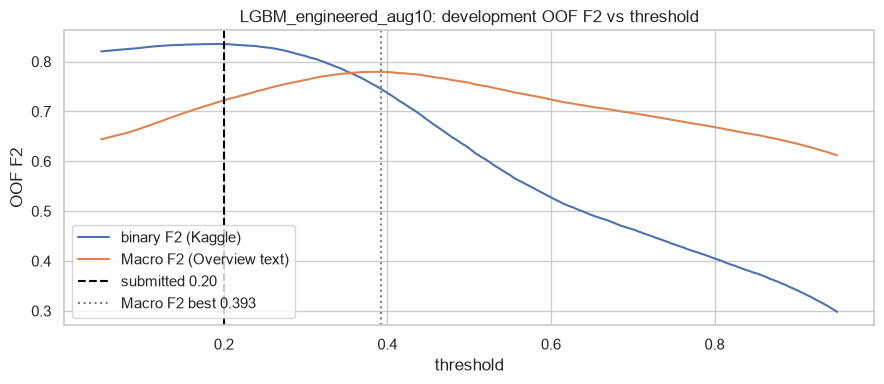

,threshold,binary_f2,macro_f2,predicted_cheater_rate
submitted (binary F2),0.2000,0.83496,0.72235,0.62536
Macro F2 optimum,0.3925,0.74519,0.77956,0.39590


Development cheater rate: 0.3493


In [10]:
# เทียบ binary F2 กับ Macro F2 ทุก threshold บน OOF ของสูตรที่ส่งจริง
binary_curve = threshold_curve(y, submitted_oof)
macro_curve = np.array([macro_f2(y, submitted_oof, t) for t in THRESHOLDS])
macro_best = float(THRESHOLDS[macro_curve.argmax()])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(THRESHOLDS, binary_curve, label='binary F2 (Kaggle)')
ax.plot(THRESHOLDS, macro_curve, label='Macro F2 (Overview text)')
ax.axvline(SUBMITTED_THRESHOLD, color='black', linestyle='--', label=f'submitted {SUBMITTED_THRESHOLD:.2f}')
ax.axvline(macro_best, color='gray', linestyle=':', label=f'Macro F2 best {macro_best:.3f}')
ax.set(xlabel='threshold', ylabel='OOF F2', title=f'{SUBMITTED}: development OOF F2 vs threshold')
ax.legend(); plt.tight_layout(); plt.show()
threshold_table = pd.DataFrame({
    'threshold': [SUBMITTED_THRESHOLD, macro_best],
    'binary_f2': [metric(y, submitted_oof, t) for t in (SUBMITTED_THRESHOLD, macro_best)],
    'macro_f2': [macro_f2(y, submitted_oof, t) for t in (SUBMITTED_THRESHOLD, macro_best)],
    'predicted_cheater_rate': [float((submitted_oof >= t).mean()) for t in (SUBMITTED_THRESHOLD, macro_best)],
}, index=['submitted (binary F2)', 'Macro F2 optimum'])
display(threshold_table.round(5))
print('Development cheater rate:', round(float(y.mean()), 4))

## 7. Audit ของสูตรที่ล็อกแล้ว

ฝึกสูตรที่ล็อกบน development ทั้งหมดแล้ววัด audit 20% ครั้งเดียว ไม่มี early stopping หรือ threshold tuning บน audit
แสดง `LGBM_engineered` (ไม่มี augmentation, threshold จาก development OOF) บน split เดียวกันเพื่อเปรียบเทียบ
รายงาน binary F₂ เป็นหลัก พร้อม F₂ ต่อคลาส classification report และ bootstrap interval

Audit engineered baseline binary F2: 0.839258 (threshold 0.1750)
Audit submitted recipe binary F2: 0.839387 (threshold 0.2) | delta: +0.000129
Audit submitted recipe Macro F2 (reference only): 0.725610
Audit ROC-AUC: 0.8932617146023974
              precision    recall  f1-score   support

  legitimate     0.9742    0.5598    0.7110     11819
     cheater     0.5425    0.9724    0.6965      6345

    accuracy                         0.7039     18164
   macro avg     0.7584    0.7661    0.7037     18164
weighted avg     0.8234    0.7039    0.7059     18164



,class,F2
0,0,0.611833
1,1,0.839387


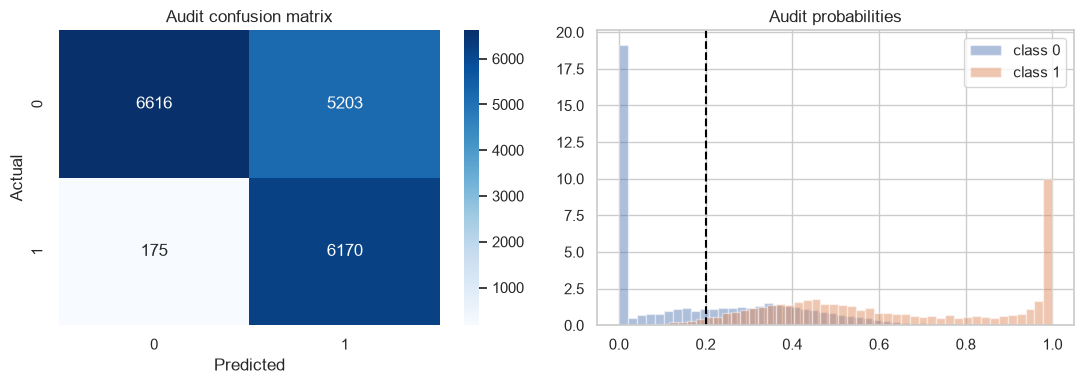

Stratified bootstrap 95% interval for audit binary F2: [0.83601 0.84319]


In [11]:
audit_models, audit_component_probs = {}, {}

def fit_fixed(frame, labels, name, rounds, n_jobs=N_JOBS):
    spec = SPECS[name]
    x_train, y_train = training_matrix(frame, labels, spec, SEED)
    model = make_model(spec, rounds, SEED, n_jobs=n_jobs)
    model.fit(x_train, y_train)
    return model

needed = set(COMPONENTS) | {'LGBM_engineered'}
for name in sorted(needed):
    rounds = LOCKED_ROUNDS.get(name, int(np.median(fold_rounds[name])))
    audit_models[name] = fit_fixed(dev, y, name, rounds)
    audit_component_probs[name] = audit_models[name].predict_proba(model_features(audit, SPECS[name]))[:, 1]
audit_proba = sum(weight * audit_component_probs[name] for name, weight in COMPONENTS.items())
audit_y = audit[TARGET].astype('int8').to_numpy()
audit_pred = (audit_proba >= WINNING_THRESHOLD).astype('int8')
baseline_threshold = float(cv_df.set_index('model').loc['LGBM_engineered', 'threshold'])
audit_baseline_f2 = metric(audit_y, audit_component_probs['LGBM_engineered'], baseline_threshold)
audit_f2 = metric(audit_y, audit_proba, WINNING_THRESHOLD)
print(f'Audit engineered baseline binary F2: {audit_baseline_f2:.6f} (threshold {baseline_threshold:.4f})')
print(f'Audit submitted recipe binary F2: {audit_f2:.6f} (threshold {WINNING_THRESHOLD}) | delta: {audit_f2 - audit_baseline_f2:+.6f}')
print(f'Audit submitted recipe Macro F2 (reference only): {macro_f2(audit_y, audit_proba, WINNING_THRESHOLD):.6f}')
print('Audit ROC-AUC:', roc_auc_score(audit_y, audit_proba))
print(classification_report(audit_y, audit_pred, target_names=['legitimate', 'cheater'], digits=4, zero_division=0))
display(pd.DataFrame({'class': [0, 1], 'F2': fbeta_score(audit_y, audit_pred, beta=2, average=None,
                                                        labels=[0, 1], zero_division=0)}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(audit_y, audit_pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set(xlabel='Predicted', ylabel='Actual', title='Audit confusion matrix')
for cls in (0, 1):
    axes[1].hist(audit_proba[audit_y == cls], bins=45, alpha=.45, density=True, label=f'class {cls}')
axes[1].axvline(WINNING_THRESHOLD, color='black', linestyle='--')
axes[1].set_title('Audit probabilities'); axes[1].legend()
plt.tight_layout(); plt.show()
# Report uncertainty without using it to re-select the model.
rng = np.random.default_rng(SEED)
boot_scores = []
class_indices = [np.flatnonzero(audit_y == cls) for cls in (0, 1)]
for _ in range(300):
    idx = np.concatenate([rng.choice(ids, size=len(ids), replace=True) for ids in class_indices])
    boot_scores.append(metric(audit_y[idx], audit_proba[idx], WINNING_THRESHOLD))
audit_ci = np.quantile(boot_scores, [.025, .975]).tolist()
print('Stratified bootstrap 95% interval for audit binary F2:', np.round(audit_ci, 5))
del audit_models


## 8. ฝึกโมเดลสุดท้ายด้วย label จริงทั้งหมด

นำ audit กลับมาเป็น training แล้วฝึกสูตรที่ล็อกบน 90,816 แถวที่มี label (รวมสำเนา masking เป็น 181,632 แถว)
ไม่ใช้ pseudo-label ของแถวที่ไม่มี target และไม่เลือก threshold จากสัดส่วนคำทำนาย test
ใช้ `n_jobs=2` เหมือนสคริปต์ที่สร้างไฟล์ที่ได้คะแนน (LightGBM ตั้ง `deterministic=True`)

ตรวจผลกับบันทึกของ repo เดิม: ไฟล์ที่ได้คะแนนทาย cheater **59.5%** ของ test
และการเปลี่ยน threshold จาก 0.38 เป็น 0.20 บน probabilities ชุดนี้เปลี่ยนคำทำนาย **4,813** แถว

In [12]:
final_models, test_component_probs, feature_importances = {}, {}, []
p_test = np.zeros(len(test), dtype=float)
for name, weight in COMPONENTS.items():
    model = fit_fixed(labeled, y_all, name, LOCKED_ROUNDS[name], n_jobs=2)
    x_test = model_features(test, SPECS[name])
    assert x_test.columns.tolist() == model.booster_.feature_name()
    probability = model.predict_proba(x_test)[:, 1]
    p_test += weight * probability
    test_component_probs[name] = probability
    final_models[name] = model
    model.booster_.save_model(str(OUTPUT_DIR / f'task1_model_{name}.txt'))
    importance = pd.DataFrame({'model': name, 'feature': x_test.columns,
                                'gain': model.booster_.feature_importance(importance_type='gain')})
    feature_importances.append(importance)
assert len(p_test) == len(test) and np.isfinite(p_test).all()
assert ((0 <= p_test) & (p_test <= 1)).all()
final_pred = (p_test >= WINNING_THRESHOLD).astype('int8')
display(pd.Series(p_test, name='test_probability').describe())
print('Predicted counts:', pd.Series(final_pred).value_counts().sort_index().to_dict())
# เทียบกับบันทึกของไฟล์ที่ได้คะแนน (outputs/probe_task1_binary_20261115 ใน repo i3artuf)
RECORDED_RATE, RECORDED_CHANGES_038_TO_020 = 0.595, 4813
predicted_rate = float(final_pred.mean())
changes_038_to_020 = int(((p_test >= .38) != (p_test >= SUBMITTED_THRESHOLD)).sum())
print(f'Predicted cheater rate: {predicted_rate:.4f} (recorded {RECORDED_RATE})')
print(f'Rows changed by threshold .38 -> .20: {changes_038_to_020:,} (recorded {RECORDED_CHANGES_038_TO_020:,})')
importance_df = pd.concat(feature_importances, ignore_index=True)
display(importance_df.sort_values('gain', ascending=False).head(20))


count    25889.000000
mean         0.348750
std          0.329334
min          0.000085
25%          0.002454
50%          0.306538
75%          0.525585
max          0.999688
Name: test_probability, dtype: float64

Predicted counts: {0: 10495, 1: 15394}
Predicted cheater rate: 0.5946 (recorded 0.595)
Rows changed by threshold .38 -> .20: 4,813 (recorded 4,813)


,model,feature,gain
30,LGBM_engineered_aug10,crosshair_placement,242104.259710
10,LGBM_engineered_aug10,reports_received,220929.870100
6,LGBM_engineered_aug10,account_age_days,166613.952853
9,LGBM_engineered_aug10,friend_network_size,140338.339191
7,LGBM_engineered_aug10,level,71474.748987
20,LGBM_engineered_aug10,game_sense_score,24921.075241
43,LGBM_engineered_aug10,reports_per_account_day,20644.797057
32,LGBM_engineered_aug10,headshot_accuracy_interaction,15827.603901
44,LGBM_engineered_aug10,reports_per_friend,15060.445181
1,LGBM_engineered_aug10,headshot_percentage,11582.649773


## 9. ส่งออกผลทำนาย

- `submissions/task1.csv`: คอลัมน์ `id,task1` โดย `id` เป็น `ANS00001`… ตามลำดับแถวของ `test.csv`
  (test แถวที่ i ↔ `ANS` แถวที่ i ตรงกับที่ใช้ในไฟล์ที่ส่ง Kaggle)
- `models/Task1/`: โมเดล LightGBM, probabilities ของ test, OOF ของ development, audit predictions และตาราง CV
- `reports/experiments/task1_run_metadata.json`: พารามิเตอร์ คะแนนภายใน hash ของข้อมูล และเวอร์ชันแพ็กเกจ

In [13]:
submission = pd.DataFrame({'row_index': np.arange(len(test), dtype='int32'),
                           'player_id': test[ID].to_numpy(copy=True), 'prediction': final_pred})
assert submission.columns.tolist() == ['row_index', 'player_id', 'prediction']
assert len(submission) == len(test)
assert np.array_equal(submission['row_index'], np.arange(len(test)))
assert submission['player_id'].astype(str).tolist() == test[ID].astype(str).tolist()
assert submission['player_id'].is_unique and not submission.isna().any().any()
assert set(submission['prediction'].unique()).issubset({0, 1})
prediction_path = OUTPUT_DIR / 'task1_predictions.csv'
submission.to_csv(prediction_path, index=False)
# ไฟล์สำหรับรวม: id ANS ตามลำดับแถวของ test
ANS_IDS = [f'ANS{i:05d}' for i in range(1, len(test) + 1)]
if sample_submission is not None:
    assert sample_submission['id'].astype(str).tolist() == ANS_IDS, 'sample_submission id order differs'
task1_csv = pd.DataFrame({'id': ANS_IDS, 'task1': final_pred.astype(int)})
task1_csv.to_csv(SUBMISSION_PATH, index=False, lineterminator='\n')
check = pd.read_csv(SUBMISSION_PATH, dtype=str)
assert check.columns.tolist() == ['id', 'task1'] and len(check) == len(test) == 25889
assert check['id'].is_unique and set(check['task1']) <= {'0', '1'}
TASK1_CSV_SHA256 = hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest()
probability_export = submission[['row_index', 'player_id']].copy()
probability_export['probability'] = p_test
probability_export['threshold'] = WINNING_THRESHOLD
probability_export.to_csv(OUTPUT_DIR / 'task1_probabilities.csv', index=False)

dev_export = pd.DataFrame({'player_id': dev[ID], 'target': y, 'fold': fold_ids,
                           'split': 'development_oof', 'selected_probability': all_probs[WINNER]})
_, _, _, cf_pred = crossfit_threshold(y, all_probs[WINNER])
dev_export['crossfit_threshold_prediction'] = cf_pred
for name, probabilities in oof_probs.items():
    dev_export[name] = probabilities
dev_export.to_csv(OUTPUT_DIR / 'task1_development_oof.csv', index=False)
pd.DataFrame({'player_id': audit[ID], 'target': audit_y, 'split': 'audit',
              'probability': audit_proba, 'prediction': audit_pred}).to_csv(OUTPUT_DIR / 'task1_audit_predictions.csv', index=False)
cv_df.to_csv(OUTPUT_DIR / 'task1_cv_results.csv', index=False)
candidates_df.to_csv(OUTPUT_DIR / 'task1_candidate_results.csv', index=False)
missing.to_csv(OUTPUT_DIR / 'task1_missing_rates.csv', index_label='feature')
importance_df.to_csv(OUTPUT_DIR / 'task1_feature_importance.csv', index=False)
pd.DataFrame({'player_id': labeled[ID], 'split': np.where(labeled.index.isin(audit_idx), 'audit', 'development')}) \
    .to_csv(OUTPUT_DIR / 'task1_split_manifest.csv', index=False)
metadata = {
    'seed': SEED, 'split_seed': 2026, 'fast_mode': FAST_MODE, 'n_splits': N_SPLITS,
    'source': str(source.relative_to(ROOT)), 'train_sha256': TRAIN_SHA256, 'test_sha256': TEST_SHA256, 'n_labeled': len(labeled), 'n_unlabeled_excluded': len(unlabeled),
    'n_development': len(dev), 'n_audit': len(audit), 'n_test': len(test),
    'auto_selection_winner': AUTO_WINNER, 'winner': WINNER, 'components': COMPONENTS, 'specifications': {name: SPECS[name] for name in COMPONENTS},
    'threshold': WINNING_THRESHOLD, 'rounds': LOCKED_ROUNDS,
    'development_crossfit_threshold_binary_f2': float(selected['crossfit_threshold_f2']),
    'development_oof_binary_f2_at_submitted_threshold': float(metric(y, submitted_oof, WINNING_THRESHOLD)),
    'audit_binary_f2': float(audit_f2), 'audit_engineered_baseline_binary_f2': float(audit_baseline_f2),
    'audit_binary_f2_bootstrap_95pct': audit_ci,
    'test_predicted_cheater_rate': predicted_rate, 'test_rows_changed_038_to_020': changes_038_to_020,
    'submission_file': str(SUBMISSION_PATH.relative_to(ROOT)), 'submission_sha256': TASK1_CSV_SHA256,
    'adversarial_auc': None if adv_auc is None else float(adv_auc),
    'test_id_order_sha256': TEST_ID_HASH, 'raw_features': features,
    'model_features': {name: model.booster_.feature_name() for name, model in final_models.items()},
    'package_versions': PACKAGE_VERSIONS, 'python_version': platform.python_version(),
    'metric': 'binary F2 of class 1: fbeta_score(beta=2) (confirmed by Kaggle threshold probe, +0.01403 public)',
    'kaggle_public_scores_using_this_task1_column': {'2026-11-15 probe': 0.74155, 'best 2026-11-17': 0.82618},
    'origin': 'Recipe from i3artuf/CPE342-kaggle-competition: task-1-anti-cheatdetection.ipynb, scripts/experiment_task1_augmentation_small_gain.py, scripts/make_task1_threshold_probe.py',
    'validation_note': 'Audit excluded from current candidate/threshold/rounds selection; this dataset was previously explored. No test labels used.',
    'missingness_note': 'Fixed 10% independent observed-value masking; no test rows or statistics used for training, augmentation, or model selection. Masking cannot simulate reduced missingness.',
    'merge_contract': 'submissions/task1.csv id,task1; test row i maps to ANS{i:05d}.',
}
REPORT_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
# Read back the actual output, including leading zeros in identifiers.
reloaded = pd.read_csv(prediction_path, dtype={'player_id': str})
pd.testing.assert_frame_equal(reloaded, submission.astype({'row_index': 'int64', 'prediction': 'int64'}))
print('SAVED:', SUBMISSION_PATH.relative_to(ROOT), '| rows:', len(task1_csv), '| SHA256:', TASK1_CSV_SHA256)
print(f'Development cross-fit binary F2: {float(selected["crossfit_threshold_f2"]):.6f}')
print(f'Audit binary F2: {audit_f2:.6f} | engineered baseline, same split: {audit_baseline_f2:.6f}')
display(task1_csv.head(10))


SAVED: submissions\task1.csv | rows: 25889 | SHA256: 3648acf5345638f6639833d2c436b37ef6a929287b996bfcde2e0583423d780b
Development cross-fit binary F2: 0.835289
Audit binary F2: 0.839387 | engineered baseline, same split: 0.839258


,id,task1
0,ANS00001,1
1,ANS00002,1
2,ANS00003,1
3,ANS00004,1
4,ANS00005,0
5,ANS00006,1
6,ANS00007,1
7,ANS00008,1
8,ANS00009,1
9,ANS00010,1


## สรุปผล

| รายการ | ผล |
|---|---:|
| สูตรที่ใช้จริง | `LGBM_engineered_aug10` (52 features + masking 10%, LightGBM 285 ต้น) |
| Threshold | 0.20 |
| Development cross-fit binary F₂ (5-fold OOF) | 0.8353 |
| Development OOF binary F₂ ที่ threshold 0.20 | 0.8350 |
| Audit binary F₂ (18,164 แถว) | 0.8394 (bootstrap 95%: 0.8360–0.8432) |
| Audit recall / precision ของคลาสคนโกง | 0.9724 / 0.5425 |
| Test ที่ทายว่าโกง | 15,394 จาก 25,889 แถว (59.46%) |
| คะแนน Kaggle public ของ submission ที่ใช้คอลัมน์ Task 1 นี้ | 0.74155 (15 พ.ย.) และ best 0.82618 (17 พ.ย.) |

**ไฟล์นี้ตรงกับที่ส่งจริงหรือไม่:** อัตราทายโกง 59.46% และจำนวนแถวที่เปลี่ยนเมื่อขยับ threshold จาก 0.38 เป็น 0.20 (4,813 แถว)
ตรงกับบันทึกของไฟล์ที่ได้คะแนนใน repo เดิม จึงยืนยันได้ว่าโน้ตบุ๊กนี้สร้างคอลัมน์ Task 1 ชุดเดียวกัน
(ไม่ได้เทียบทีละแถวกับไฟล์ที่ส่ง เพราะไฟล์นั้นไม่อยู่ใน repo)

**การเปรียบเทียบ candidates:** ทุก candidate ได้ cross-fit binary F₂ อยู่ในช่วง 0.8348–0.8361 ต่างกันไม่เกิน 0.0013
ซึ่งน้อยกว่าเกณฑ์ `MIN_GAIN` 0.002 และใกล้กับส่วนเบี่ยงเบนราย fold (~0.0015) การคัดเลือกอัตโนมัติจึงคง reference (`LGBM_raw`)
ส่วนสูตรที่ส่งจริงต่ำกว่า reference 0.0002 บน development แต่สูงกว่า engineered baseline บน audit 0.0001 ถือว่าเท่ากันในระดับ noise
จึงใช้สูตรที่มีคะแนน Kaggle ยืนยันแล้ว แทนการเปลี่ยนโมเดลจากความต่างที่วัดไม่ได้

**ผลของ metric:** threshold 0.20 ได้ binary F₂ 0.8350 เทียบกับ 0.7452 ที่ threshold 0.3925 ซึ่งเป็นจุดที่ Macro F₂ สูงสุด
F₂ ให้น้ำหนัก recall มากกว่า precision โมเดลจึงทายว่าโกงมากกว่าสัดส่วนจริง (34.9%) เพื่อจับคนโกงได้เกือบทั้งหมด

**ข้อจำกัด:** OOF และ audit เป็นคะแนนภายในจากข้อมูลที่กลุ่มเคยสำรวจมาแล้ว ไม่ใช่ external validation
และ train/test มีสัดส่วนค่าว่างต่างกัน คะแนนบน test จึงอาจต่างจากคะแนนภายใน
